In [8]:
import os
import cv2
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.metrics import structural_similarity as ssim
from tqdm import tqdm

In [12]:
PATH_TRAIN_ASLI = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi - Coding\V4 - Splitted Dataset\train"
PATH_TRAIN_GAN = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi - Coding\V4 - Splitted Dataset\train_gan_sintesis"
CLASSES_TO_EVALUATE = ['SMP DW', 'CK']
IMG_SIZE = (128, 128) # Dimensi standar resolusi GAN
sns.set_theme(style="whitegrid")

In [13]:

def calculate_average_ssim(class_name):
    """
    Fungsi untuk menghitung rata-rata skor SSIM antara gambar asli dan gambar sintetik (GAN).
    Pendekatan: Membandingkan setiap gambar sintetik dengan sebuah gambar asli
    yang diambil secara acak dari distribusi kelas yang sama untuk mengukur fidelitas spasial.
    """
    dir_asli = os.path.join(PATH_TRAIN_ASLI, class_name)
    dir_gan = os.path.join(PATH_TRAIN_GAN, class_name)
    
    if not os.path.exists(dir_asli) or not os.path.exists(dir_gan):
        print(f"⚠️ Peringatan: Direktori untuk kelas {class_name} tidak ditemukan.")
        return None

    # Ekstraksi daftar file yang valid
    asli_images = [f for f in os.listdir(dir_asli) if f.lower().endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('aug_')]
    gan_images = [f for f in os.listdir(dir_gan) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    
    if not asli_images or not gan_images:
        print(f"⚠️ Peringatan: Himpunan gambar tidak mencukupi pada kelas {class_name}.")
        return None

    ssim_scores = []
    
    print(f"\n🔍 Memulai Evaluasi SSIM untuk Kelas: {class_name}")
    print(f"   -> Populasi Gambar GAN: {len(gan_images)}")
    print(f"   -> Populasi Gambar Asli (Referensi): {len(asli_images)}")
    
    # Iterasi untuk setiap matriks gambar sintetik
    for gan_img_name in tqdm(gan_images, desc=f"Menghitung SSIM ({class_name})"):
        gan_path = os.path.join(dir_gan, gan_img_name)
        gan_img = cv2.imread(gan_path)
        
        if gan_img is None:
            continue
            
        # Prapemrosesan: Resize gambar GAN ke 128x128 dan konversi ke ruang warna RGB
        gan_img = cv2.resize(gan_img, IMG_SIZE)
        gan_img = cv2.cvtColor(gan_img, cv2.COLOR_BGR2RGB)
        
        # Pengambilan acak matriks gambar asli sebagai pembanding referensi (Ground Truth features)
        random_asli_name = random.choice(asli_images)
        asli_path = os.path.join(dir_asli, random_asli_name)
        asli_img = cv2.imread(asli_path)
        
        if asli_img is None:
            continue
            
        # Prapemrosesan: Resize gambar asli agar memiliki dimensi absolut yang ekuivalen
        asli_img = cv2.resize(asli_img, IMG_SIZE)
        asli_img = cv2.cvtColor(asli_img, cv2.COLOR_BGR2RGB)
        
        # Kalkulasi Metrik Struktural (SSIM) untuk format multi-saluran (RGB)
        # Parameter channel_axis=-1 menegaskan komputasi berjalan pada kedalaman 3 warna (RGB)
        score, _ = ssim(asli_img, gan_img, channel_axis=-1, full=True)
        ssim_scores.append(score)
        
    avg_ssim = np.mean(ssim_scores) if ssim_scores else 0.0
    max_ssim = np.max(ssim_scores) if ssim_scores else 0.0
    min_ssim = np.min(ssim_scores) if ssim_scores else 0.0
    
    print(f"✅ Rata-rata Skor SSIM untuk {class_name}: {avg_ssim:.4f}")
    return {
        'Class': class_name,
        'Mean_SSIM': round(avg_ssim, 4),
        'Max_SSIM': round(max_ssim, 4),
        'Min_SSIM': round(min_ssim, 4),
        'Total_Evaluated': len(ssim_scores)
    }


🔍 Memulai Evaluasi SSIM untuk Kelas: SMP DW
   -> Populasi Gambar GAN: 567
   -> Populasi Gambar Asli (Referensi): 201


Menghitung SSIM (SMP DW): 100%|██████████| 567/567 [01:03<00:00,  8.92it/s]


✅ Rata-rata Skor SSIM untuk SMP DW: 0.0389

🔍 Memulai Evaluasi SSIM untuk Kelas: CK
   -> Populasi Gambar GAN: 570
   -> Populasi Gambar Asli (Referensi): 278


Menghitung SSIM (CK): 100%|██████████| 570/570 [00:21<00:00, 26.05it/s]
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_6012\140995212.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Class', y='Mean_SSIM', data=df_results, palette='mako')


✅ Rata-rata Skor SSIM untuk CK: 0.0239

🏆 REKAPITULASI EVALUASI STRUKTURAL (SSIM)
 Class  Mean_SSIM  Max_SSIM  Min_SSIM  Total_Evaluated
SMP DW     0.0389    0.1135   -0.0007              567
    CK     0.0239    0.0719   -0.0166              570


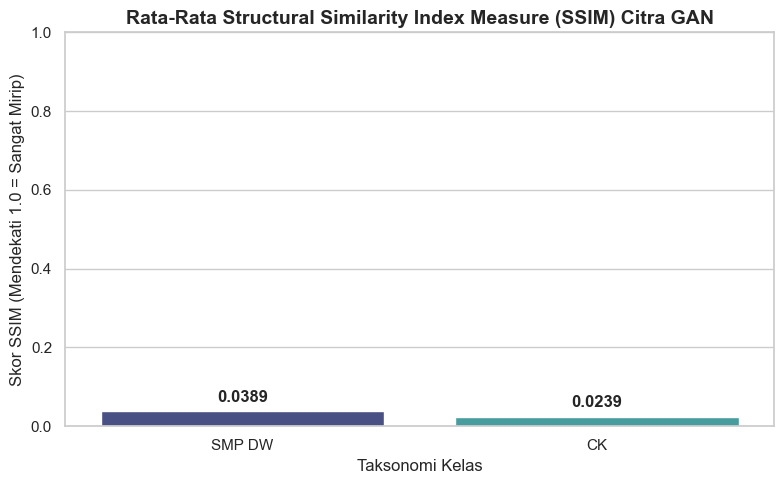

In [14]:
# ==========================================
# EKSEKUSI PIPELINE EVALUASI SSIM
# ==========================================
def main_ssim_evaluation():
    results = []
    for class_name in CLASSES_TO_EVALUATE:
        res = calculate_average_ssim(class_name)
        if res:
            results.append(res)
            
    # Konstruksi DataFrame Laporan Evaluasi
    df_results = pd.DataFrame(results)
    print("\n" + "="*50)
    print("🏆 REKAPITULASI EVALUASI STRUKTURAL (SSIM)")
    print("="*50)
    print(df_results.to_string(index=False))
    
    # Visualisasi Hasil Komputasi ke dalam Bar Chart
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(x='Class', y='Mean_SSIM', data=df_results, palette='mako')
    plt.title('Rata-Rata Structural Similarity Index Measure (SSIM) Citra GAN', fontsize=14, fontweight='bold')
    plt.xlabel('Taksonomi Kelas', fontsize=12)
    plt.ylabel('Skor SSIM (Mendekati 1.0 = Sangat Mirip)', fontsize=12)
    plt.ylim(0, 1.0)
    
    # Injeksi label nilai absolut pada diagram
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.4f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 10), 
                    textcoords='offset points', fontweight='bold')
                    
    plt.tight_layout()
    # Pilihan penyimpanan grafik log
    plt.savefig('Grafik_Evaluasi_SSIM.png', dpi=300)
    plt.show()

if __name__ == "__main__":
    main_ssim_evaluation()